In [22]:
#Agglomerative Clustering
print("Agglomerative Clustering")

Agglomerative Clustering


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

print("Libraries Imported Successfully!")

In [6]:
#Load Dataset
df = pd.read_csv("segmentation data.csv")

print("Dataset Loaded Successfully!")

print("\nFirst 5 Rows:")
print(df.head())

Dataset Loaded Successfully!

First 5 Rows:
          ID  Sex  Marital status  Age  Education  Income  Occupation  \
0  100000001    0               0   67          2  124670           1   
1  100000002    1               1   22          1  150773           1   
2  100000003    0               0   49          1   89210           0   
3  100000004    0               0   45          1  171565           1   
4  100000005    0               0   53          1  149031           1   

   Settlement size  
0                2  
1                2  
2                0  
3                1  
4                1  


In [7]:
# Cell 3: Explore Dataset
print("Dataset Shape:")
print(df.shape)

Dataset Shape:
(2000, 8)


In [8]:
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['ID', 'Sex', 'Marital status', 'Age', 'Education', 'Income', 'Occupation', 'Settlement size']


In [9]:
print("\nDataset Information:")
print(df.info())


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   ID               2000 non-null   int64
 1   Sex              2000 non-null   int64
 2   Marital status   2000 non-null   int64
 3   Age              2000 non-null   int64
 4   Education        2000 non-null   int64
 5   Income           2000 non-null   int64
 6   Occupation       2000 non-null   int64
 7   Settlement size  2000 non-null   int64
dtypes: int64(8)
memory usage: 125.1 KB
None


In [10]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
ID                 0
Sex                0
Marital status     0
Age                0
Education          0
Income             0
Occupation         0
Settlement size    0
dtype: int64


In [11]:
print("\nStatistical Summary:")
print(df.describe())


Statistical Summary:
                 ID          Sex  Marital status          Age   Education  \
count  2.000000e+03  2000.000000     2000.000000  2000.000000  2000.00000   
mean   1.000010e+08     0.457000        0.496500    35.909000     1.03800   
std    5.774946e+02     0.498272        0.500113    11.719402     0.59978   
min    1.000000e+08     0.000000        0.000000    18.000000     0.00000   
25%    1.000005e+08     0.000000        0.000000    27.000000     1.00000   
50%    1.000010e+08     0.000000        0.000000    33.000000     1.00000   
75%    1.000015e+08     1.000000        1.000000    42.000000     1.00000   
max    1.000020e+08     1.000000        1.000000    76.000000     3.00000   

              Income   Occupation  Settlement size  
count    2000.000000  2000.000000      2000.000000  
mean   120954.419000     0.810500         0.739000  
std     38108.824679     0.638587         0.812533  
min     35832.000000     0.000000         0.000000  
25%     97663.25000

In [12]:
#Feature Selection

X = df[['Age', 'Income']]

print("Selected Features:")
print(X.head())

Selected Features:
   Age  Income
0   67  124670
1   22  150773
2   49   89210
3   45  171565
4   53  149031


In [13]:
print("\nFeature Shape:")
print(X.shape)


Feature Shape:
(2000, 2)


In [14]:
#Feature Scaling

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature Scaling Completed Successfully!")

print("\nScaled Data (First 5 Rows):")
print(X_scaled[:5])

Feature Scaling Completed Successfully!

Scaled Data (First 5 Rows):
[[ 2.65361447  0.09752361]
 [-1.18713209  0.78265438]
 [ 1.11731585 -0.83320224]
 [ 0.77591616  1.32838624]
 [ 1.45871554  0.73693175]]


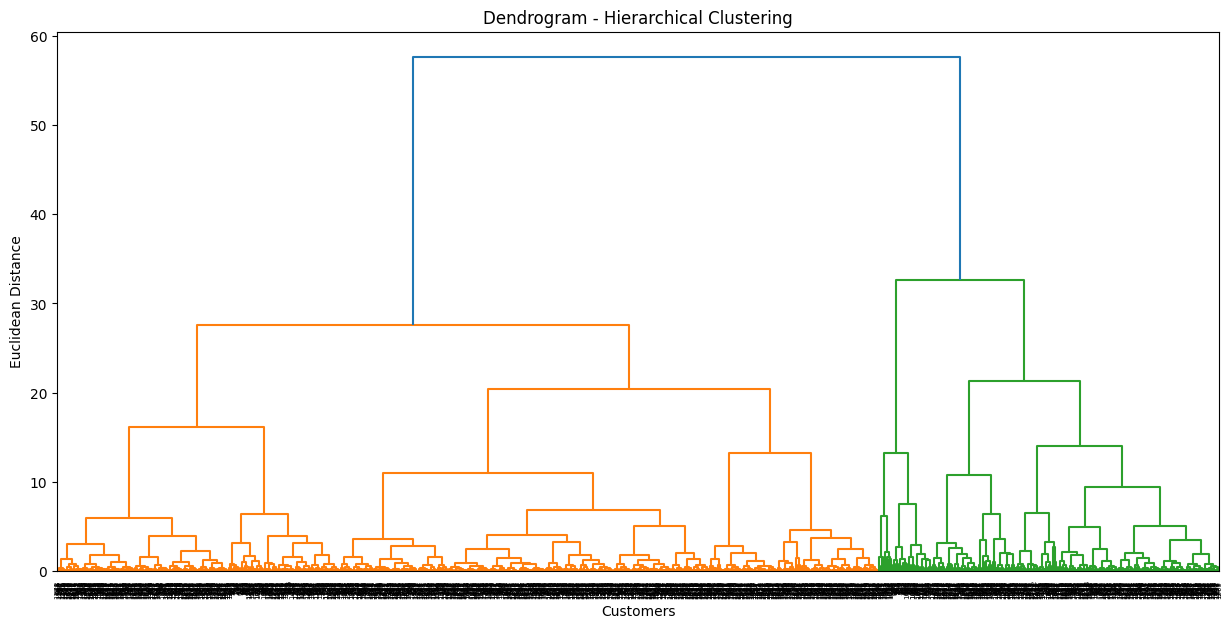

In [15]:
#Create Dendrogram

plt.figure(figsize=(15, 7))

dendrogram(
    linkage(X_scaled, method='ward')
)

plt.title("Dendrogram - Hierarchical Clustering")
plt.xlabel("Customers")
plt.ylabel("Euclidean Distance")

plt.show()

In [16]:
#Find the Best Number of Clusters

from sklearn.metrics import silhouette_score

for k in range(2, 9):
    model = AgglomerativeClustering(n_clusters=k, linkage='ward')

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    print(f"Clusters: {k}, Silhouette Score: {score:.4f}")

Clusters: 2, Silhouette Score: 0.4455
Clusters: 3, Silhouette Score: 0.4473
Clusters: 4, Silhouette Score: 0.2878
Clusters: 5, Silhouette Score: 0.2955
Clusters: 6, Silhouette Score: 0.3038
Clusters: 7, Silhouette Score: 0.2897
Clusters: 8, Silhouette Score: 0.3047


In [17]:
#Build Final Hierarchical Clustering Model

hierarchical_model = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

df['Hierarchical_Cluster'] = hierarchical_model.fit_predict(X_scaled)

print("Hierarchical Clustering Model Created Successfully!")

print("\nCluster Counts:")
print(df['Hierarchical_Cluster'].value_counts().sort_index())

Hierarchical Clustering Model Created Successfully!

Cluster Counts:
Hierarchical_Cluster
0    1413
1     494
2      93
Name: count, dtype: int64


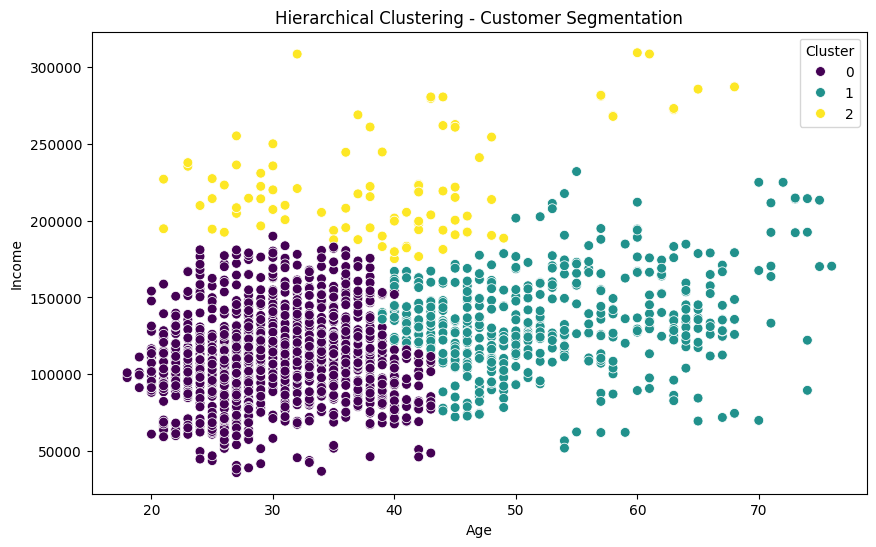

In [18]:
#Visualize Hierarchical Clusters

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Age',
    y='Income',
    hue='Hierarchical_Cluster',
    palette='viridis',
    s=50
)

plt.title("Hierarchical Clustering - Customer Segmentation")
plt.xlabel("Age")
plt.ylabel("Income")
plt.legend(title="Cluster")

plt.show()

In [19]:
#Analyze Customer Clusters

cluster_analysis = df.groupby('Hierarchical_Cluster').agg({
    'Age': 'mean',
    'Income': 'mean',
    'ID': 'count'
}).round(2)

cluster_analysis.rename(
    columns={'ID': 'Customer_Count'},
    inplace=True
)

print("Hierarchical Cluster Analysis:")
print(cluster_analysis)

Hierarchical Cluster Analysis:
                        Age     Income  Customer_Count
Hierarchical_Cluster                                  
0                     29.97  109666.32            1413
1                     52.12  133665.01             494
2                     40.06  224944.18              93


In [20]:
#Model Evaluation

from sklearn.metrics import silhouette_score, davies_bouldin_score

silhouette = silhouette_score(X_scaled, df['Hierarchical_Cluster'])

davies = davies_bouldin_score(X_scaled, df['Hierarchical_Cluster'])

print("Hierarchical Clustering Model Evaluation")
print("----------------------------------------")
print(f"Silhouette Score: {silhouette:.4f}")
print(f"Davies-Bouldin Score: {davies:.4f}")

Hierarchical Clustering Model Evaluation
----------------------------------------
Silhouette Score: 0.4473
Davies-Bouldin Score: 0.8449


In [21]:
# Save Cluster Results

df.to_csv("hierarchical_clustering_results.csv", index=False)

print("Cluster results saved successfully!")
print("File: hierarchical_clustering_results.csv")

Cluster results saved successfully!
File: hierarchical_clustering_results.csv


In [23]:
print("Divisive Clustering")

Divisive Clustering


In [24]:
# Divisive Clustering - Import Libraries

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("Divisive Clustering Libraries Imported Successfully!")

Divisive Clustering Libraries Imported Successfully!


In [26]:
# Divisive Clustering - Prepare Data

X_divisive = X_scaled.copy()
print("Data Prepared for Divisive Clustering!")

Data Prepared for Divisive Clustering!


In [27]:
print("Dataset Shape:", X_divisive.shape)

Dataset Shape: (2000, 2)


In [28]:
# Divisive Clustering - Initial Split

# Start with all customers in one cluster
clusters = [X_divisive]

# Split the data into 2 clusters using K-Means
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)

labels = kmeans.fit_predict(X_divisive)

# Separate customers into two clusters
cluster_0 = X_divisive[labels == 0]
cluster_1 = X_divisive[labels == 1]

clusters = [cluster_0, cluster_1]

print("Divisive Clustering: Initial Split Completed!")
print("Number of Clusters:", len(clusters))
print("Cluster 0 Size:", len(cluster_0))
print("Cluster 1 Size:", len(cluster_1))

Divisive Clustering: Initial Split Completed!
Number of Clusters: 2
Cluster 0 Size: 1355
Cluster 1 Size: 645


In [29]:
# Divisive Clustering - Split Larger Cluster

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)

labels_0 = kmeans.fit_predict(cluster_0)

cluster_0a = cluster_0[labels_0 == 0]
cluster_0b = cluster_0[labels_0 == 1]

# Keep the smaller original cluster unchanged
clusters = [cluster_0a, cluster_0b, cluster_1]

print("Larger Cluster Split Successfully!")
print("Total Clusters:", len(clusters))
print("Cluster 0A Size:", len(cluster_0a))
print("Cluster 0B Size:", len(cluster_0b))
print("Cluster 1 Size:", len(cluster_1))

Larger Cluster Split Successfully!
Total Clusters: 3
Cluster 0A Size: 801
Cluster 0B Size: 554
Cluster 1 Size: 645


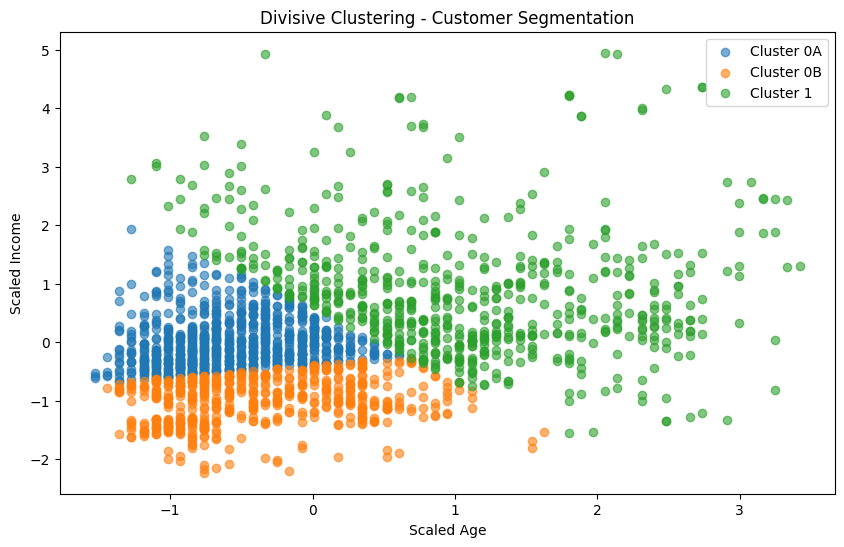

In [30]:
# Divisive Clustering - Visualization

plt.figure(figsize=(10, 6))

plt.scatter(
    cluster_0a[:, 0],
    cluster_0a[:, 1],
    label='Cluster 0A',
    alpha=0.6
)

plt.scatter(
    cluster_0b[:, 0],
    cluster_0b[:, 1],
    label='Cluster 0B',
    alpha=0.6
)

plt.scatter(
    cluster_1[:, 0],
    cluster_1[:, 1],
    label='Cluster 1',
    alpha=0.6
)

plt.title("Divisive Clustering - Customer Segmentation")
plt.xlabel("Scaled Age")
plt.ylabel("Scaled Income")
plt.legend()
plt.show()

In [33]:
# Divisive Clustering - Model Evaluation

divisive_labels = np.empty(len(X_divisive), dtype=int)

# Assign labels to the first split's Cluster 0
divisive_labels[labels == 0] = labels_0

# Assign label 2 to the first split's Cluster 1
divisive_labels[labels == 1] = 2

# Calculate Silhouette Score
silhouette = silhouette_score(X_divisive, divisive_labels)

print("Divisive Clustering Evaluation")
print("--------------------------------")
print("Total Customers:", len(divisive_labels))
print("Number of Clusters:", len(np.unique(divisive_labels)))
print(f"Silhouette Score: {silhouette:.4f}")

Divisive Clustering Evaluation
--------------------------------
Total Customers: 2000
Number of Clusters: 3
Silhouette Score: 0.2743


In [34]:
# Divisive Clustering - Save Results

df['Divisive_Cluster'] = divisive_labels

df.to_csv("divisive_clustering_results.csv", index=False)

print("Divisive Clustering Results Saved Successfully!")
print("File: divisive_clustering_results.csv")

print("\nCluster Counts:")
print(df['Divisive_Cluster'].value_counts().sort_index())

Divisive Clustering Results Saved Successfully!
File: divisive_clustering_results.csv

Cluster Counts:
Divisive_Cluster
0    801
1    554
2    645
Name: count, dtype: int64


In [35]:
# Compare Both Hierarchical Methods

comparison = pd.DataFrame({
    'Method': ['Agglomerative', 'Divisive'],
    'Number of Clusters': [
        len(np.unique(df['Hierarchical_Cluster'])),
        len(np.unique(df['Divisive_Cluster']))
    ],
    'Silhouette Score': [
        silhouette_score(X_scaled, df['Hierarchical_Cluster']),
        silhouette_score(X_divisive, df['Divisive_Cluster'])
    ]
})

print("Hierarchical Clustering Comparison")
print(comparison.round(4))

Hierarchical Clustering Comparison
          Method  Number of Clusters  Silhouette Score
0  Agglomerative                   3            0.4473
1       Divisive                   3            0.2743


In [36]:
# Final Hierarchical Clustering Summary

print("HIERARCHICAL CLUSTERING PROJECT")
print("================================")

print("\n1. Agglomerative Clustering")
print("Number of Clusters:", df['Hierarchical_Cluster'].nunique())
print("Silhouette Score:",
      round(silhouette_score(X_scaled, df['Hierarchical_Cluster']), 4))

print("\n2. Divisive Clustering")
print("Number of Clusters:", df['Divisive_Cluster'].nunique())
print("Silhouette Score:",
      round(silhouette_score(X_divisive, df['Divisive_Cluster']), 4))

print("\nBoth Hierarchical Clustering methods completed!")

HIERARCHICAL CLUSTERING PROJECT

1. Agglomerative Clustering
Number of Clusters: 3
Silhouette Score: 0.4473

2. Divisive Clustering
Number of Clusters: 3
Silhouette Score: 0.2743

Both Hierarchical Clustering methods completed!
